In [1]:
# Cài đặt unrar nếu chưa có
!apt-get install unrar

# Giải nén file vào thư mục hiện tại (/content/)
!unrar x skin-disease-datasaet.rar /content/

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
unrar is already the newest version (1:7.0.7-1build1).
0 upgraded, 0 newly installed, 0 to remove and 33 not upgraded.

UNRAR 7.00 freeware      Copyright (c) 1993-2024 Alexander Roshal


Extracting from skin-disease-datasaet.rar

Creating    /content/skin-disease-datasaet                            OK
Creating    /content/skin-disease-datasaet/test_set                   OK
Creating    /content/skin-disease-datasaet/test_set/BA- cellulitis    OK
Extracting  /content/skin-disease-datasaet/test_set/BA- cellulitis/BA- cellulitis (1).webp       0%  OK 
Extracting  /content/skin-disease-datasaet/test_set/BA- cellulitis/BA- cellulitis (104).jpg       0%  OK 
Extracting  /content/skin-disease-datasaet/test_set/BA- cellulitis/BA- cellulitis (106).jpg       0%  OK 
Extracting  /content/skin-disease-datasaet/test_set/BA- cellulitis/BA- cellulitis (115).jpg       0%

In [2]:
# Tải mô hình Sam_vit_b_01ec64
!rm -f /content/sam_vit_b_01ec64.pth

!wget -O /content/sam_vit_b_01ec64.pth \
https://dl.fbaipublicfiles.com/segment_anything/sam_vit_b_01ec64.pth

--2026-11-05 01:20:59--  https://dl.fbaipublicfiles.com/segment_anything/sam_vit_b_01ec64.pth
Resolving dl.fbaipublicfiles.com (dl.fbaipublicfiles.com)... 65.9.168.81, 65.9.168.52, 65.9.168.4, ...
Connecting to dl.fbaipublicfiles.com (dl.fbaipublicfiles.com)|65.9.168.81|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 375042383 (358M) [binary/octet-stream]
Saving to: ‘/content/sam_vit_b_01ec64.pth’

/content/sam_vit_b_ 100%[===================>] 357.67M   240MB/s    in 1.5s    

2026-11-05 01:21:00 (240 MB/s) - ‘/content/sam_vit_b_01ec64.pth’ saved [375042383/375042383]



In [3]:
!pip install git+https://github.com/facebookresearch/segment-anything.git

  Cloning https://github.com/facebookresearch/segment-anything.git to /tmp/pip-req-build-0w2rmp59
  Running command git clone --filter=blob:none --quiet https://github.com/facebookresearch/segment-anything.git /tmp/pip-req-build-0w2rmp59
  Resolved https://github.com/facebookresearch/segment-anything.git to commit dca509fe793f601edb92606367a655c15ac00fdf
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for segment_anything: filename=segment_anything-1.0-py3-none-any.whl size=36637 sha256=bc425553d799f0feaa0bbc7d39f7c0f7099fcabfe1e47d98435a5f335c8e9b61
  Stored in directory: /tmp/pip-ephem-wheel-cache-4q5jlzca/wheels/5d/7b/4a/c7fda89f2e27647dd0816f51ea103992b1b6f0f53ad234895c
Successfully built segment_anything


SAM ViT-B BOX PROMPT MASK GENERATOR (NO U-NET TRAINING)

Tìm thấy 924 ảnh trong thư mục: /content/skin-disease-datasaet/train_set

SAM device: cuda

BẮT ĐẦU TẠO VÀ LƯU SAM BOX-PROMPT MASKS


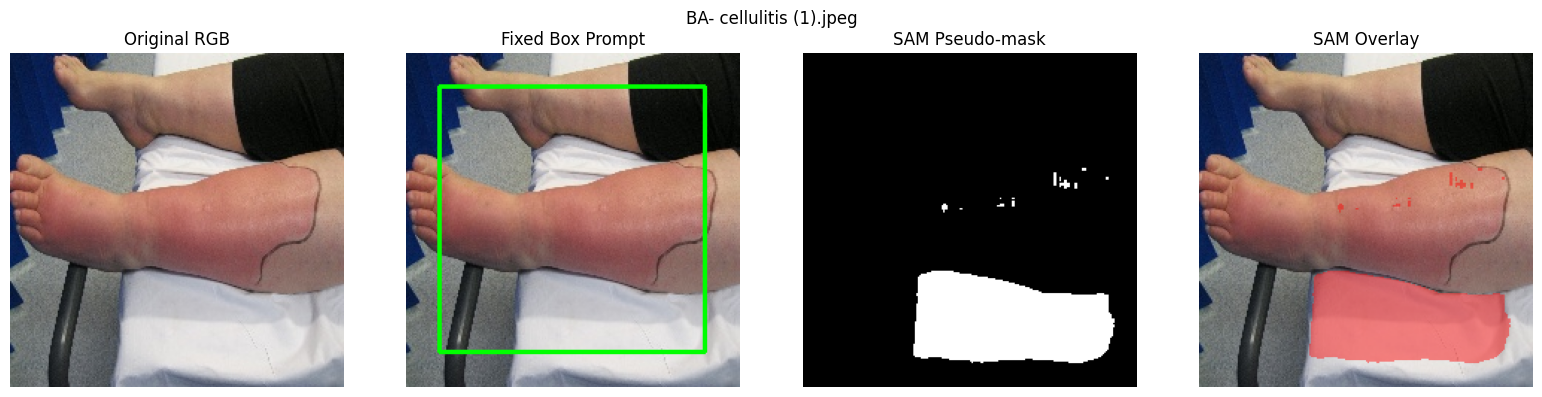

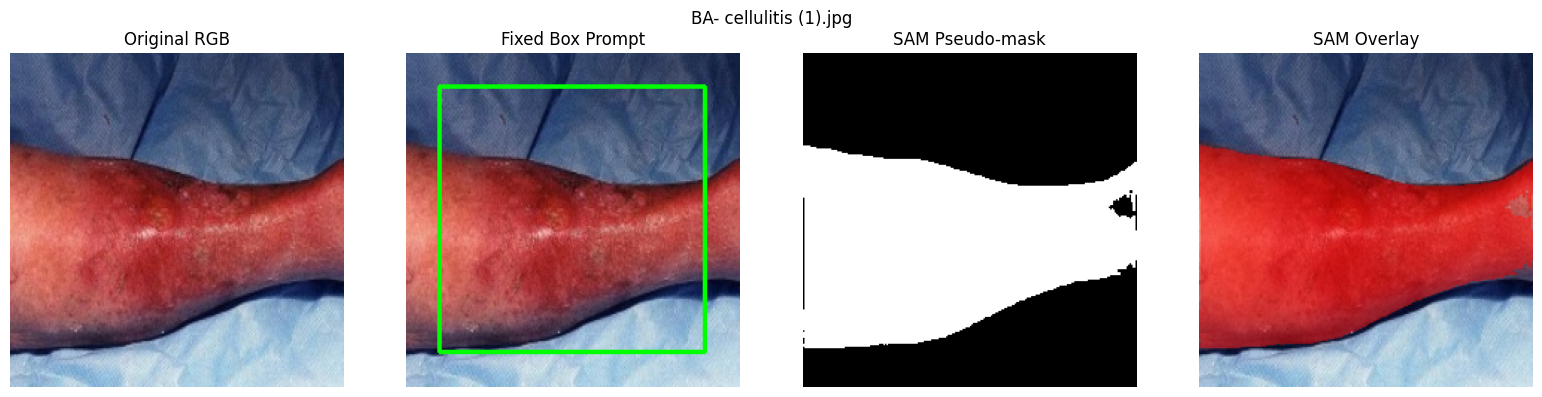

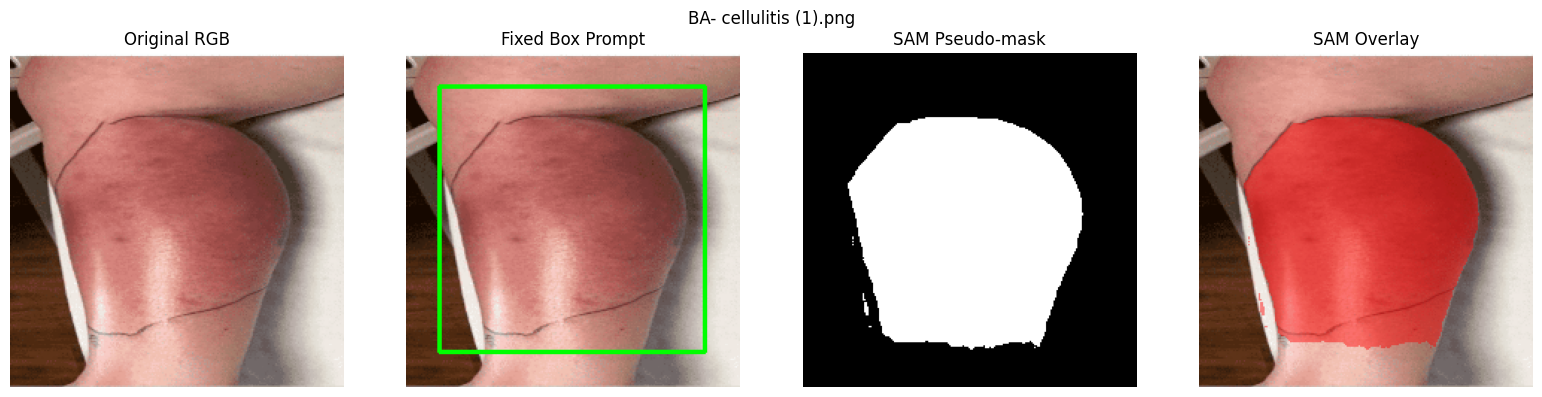

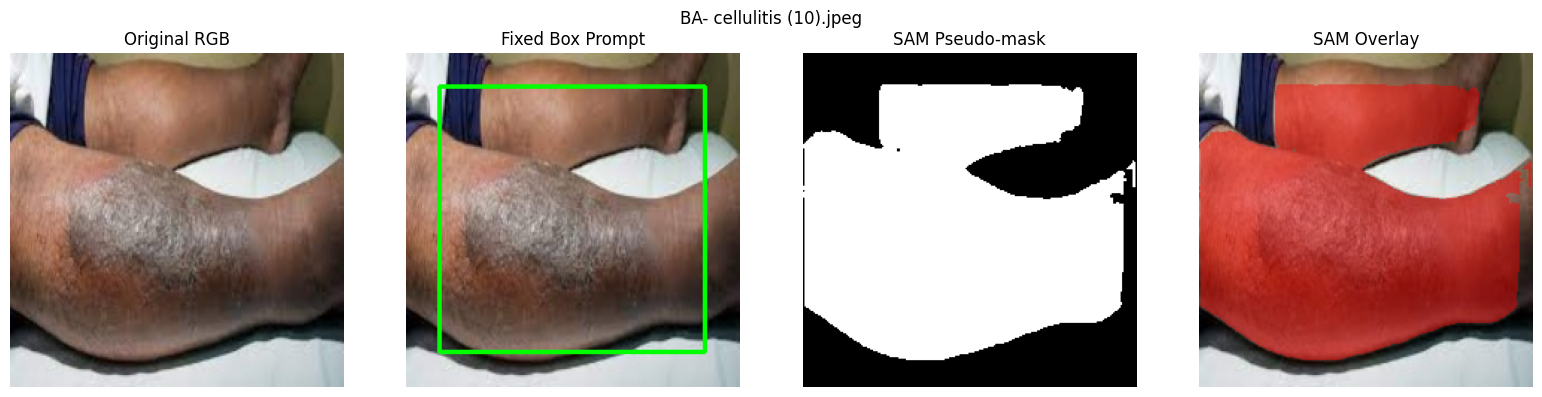

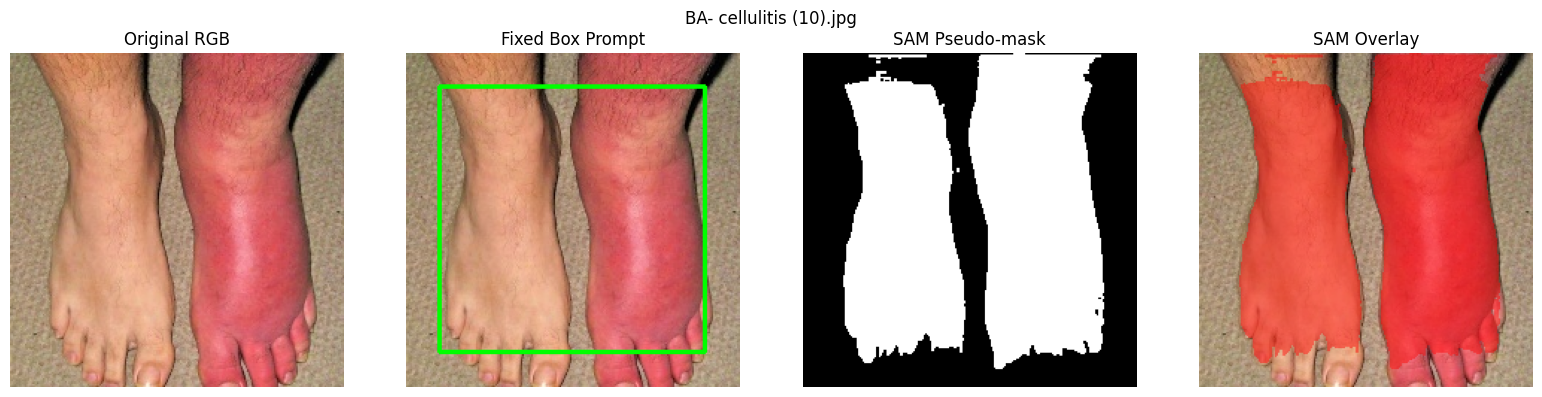

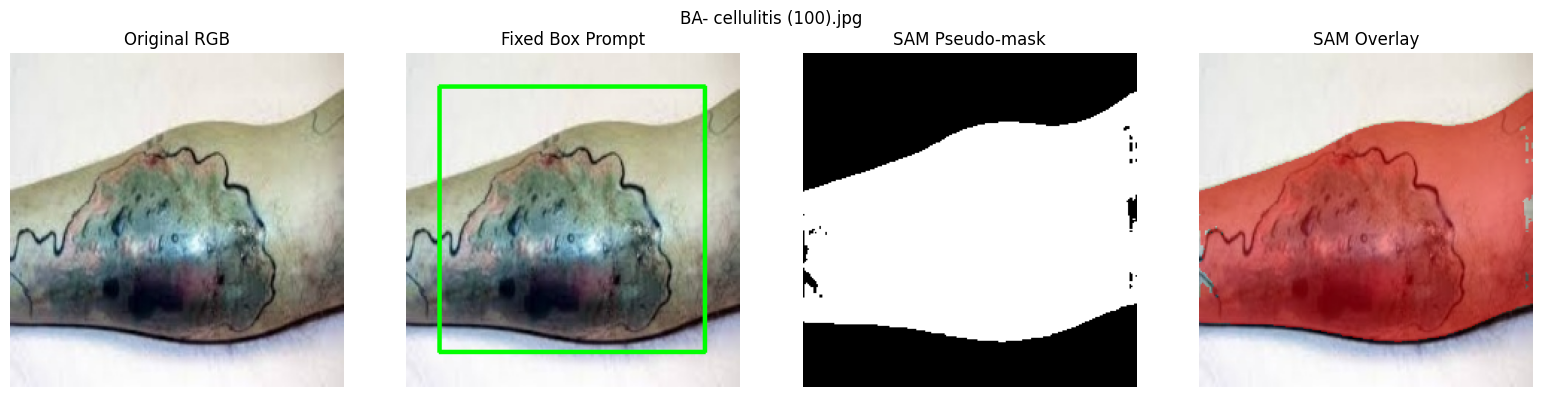

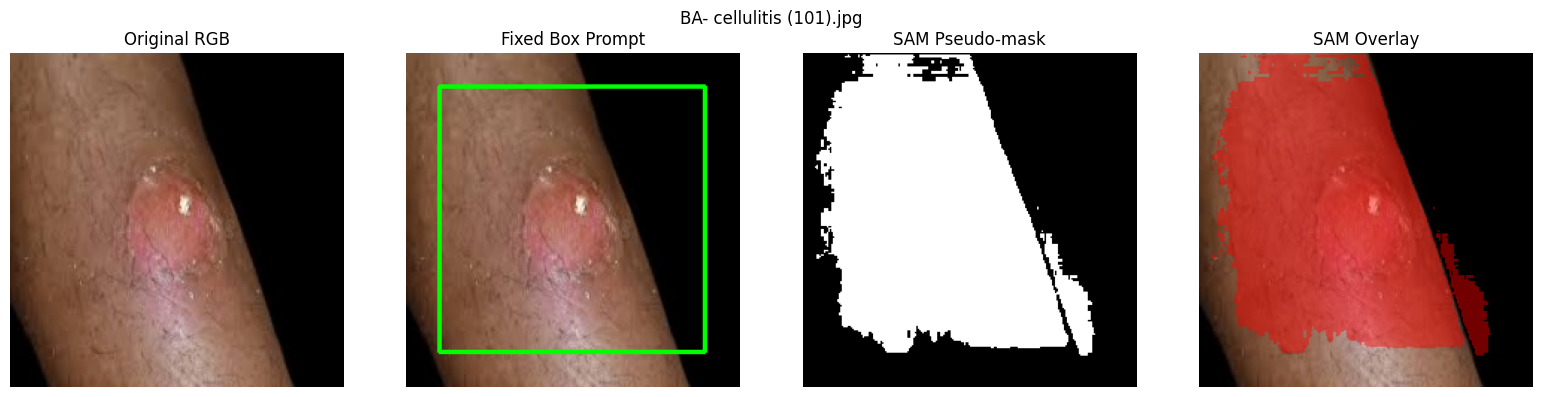

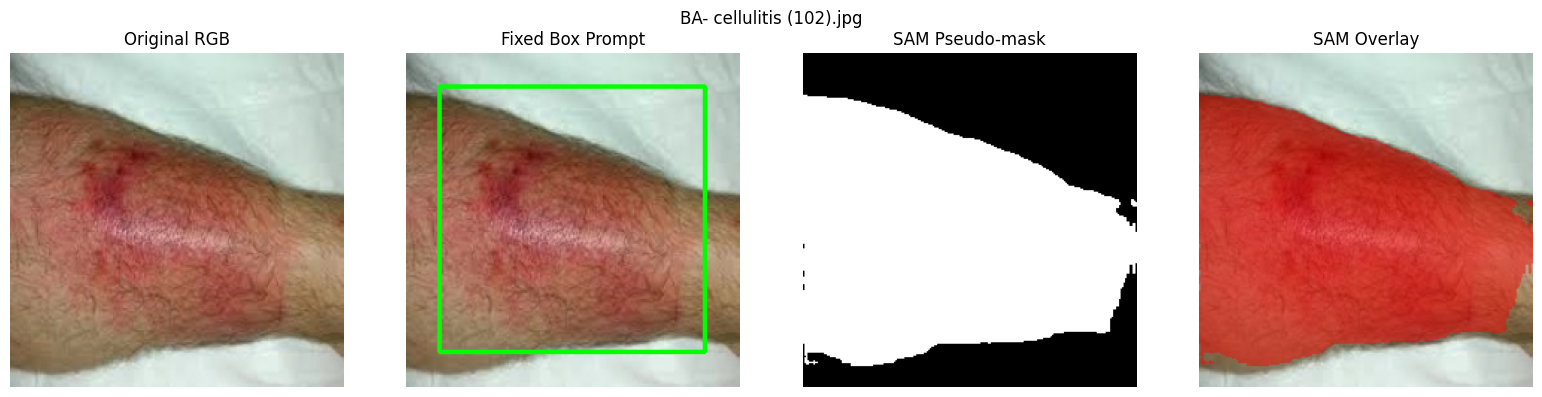

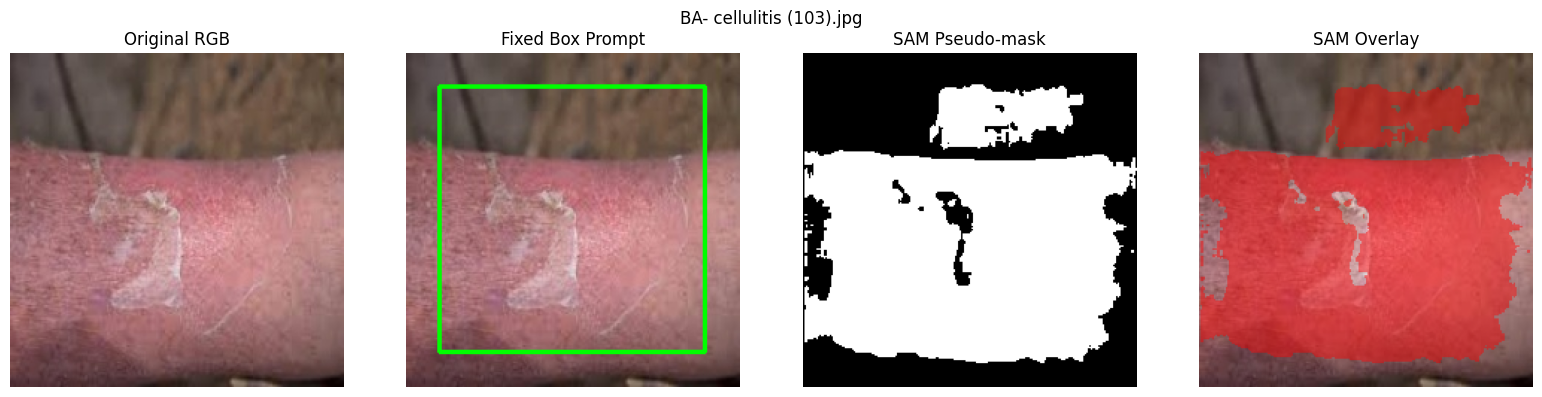

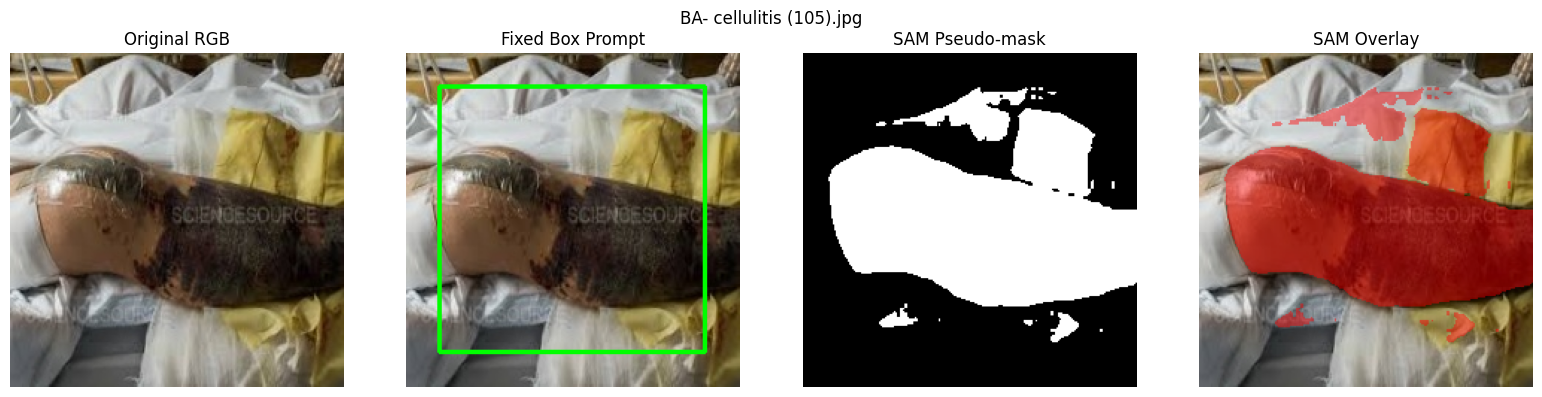

Đã xử lý 10/924 ảnh | SAM score=0.9452
Đã xử lý 20/924 ảnh | SAM score=0.9486
Đã xử lý 30/924 ảnh | SAM score=0.9779
Đã xử lý 40/924 ảnh | SAM score=0.8691
Đã xử lý 50/924 ảnh | SAM score=0.9804
Đã xử lý 60/924 ảnh | SAM score=0.8569
Đã xử lý 70/924 ảnh | SAM score=0.9439
Đã xử lý 80/924 ảnh | SAM score=0.9477
Đã xử lý 90/924 ảnh | SAM score=0.8662
Đã xử lý 100/924 ảnh | SAM score=0.9489
Đã xử lý 110/924 ảnh | SAM score=0.9922
Đã xử lý 120/924 ảnh | SAM score=0.9858
Đã xử lý 130/924 ảnh | SAM score=0.9785
Đã xử lý 140/924 ảnh | SAM score=0.9702
Đã xử lý 150/924 ảnh | SAM score=0.9544
Đã xử lý 160/924 ảnh | SAM score=0.9121
Đã xử lý 170/924 ảnh | SAM score=0.9559
Đã xử lý 180/924 ảnh | SAM score=0.9618
Đã xử lý 190/924 ảnh | SAM score=0.9797
Đã xử lý 200/924 ảnh | SAM score=0.9676
Đã xử lý 210/924 ảnh | SAM score=0.9487
Đã xử lý 220/924 ảnh | SAM score=0.9668
Đã xử lý 230/924 ảnh | SAM score=0.8173
Đã xử lý 240/924 ảnh | SAM score=0.9331
Đã xử lý 250/924 ảnh | SAM score=0.8987
Đã xử lý 

In [4]:
import os
import glob
import random
import time
import warnings

import cv2
import numpy as np
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

# ================================================================
# 1. Cấu Hình
# ================================================================

# Thư mục chứa ảnh gốc cần tạo mask
DATA_DIR = r"/content/skin-disease-datasaet/train_set"

# Đường dẫn checkpoint SAM ViT-B
SAM_CHECKPOINT = r"/content/sam_vit_b_01ec64.pth"
SAM_MODEL_TYPE = "vit_b"

# Thư mục lưu kết quả mask
MASK_SAVE_DIR = "output_pseudo_masks_sam_box"
VISUALIZATION_DIR = "sam_box_visual_checks"

RANDOM_SEED = 42

# Tham số prompt hộp cố định (chiếm 80% kích thước ảnh ở chính giữa)
BOX_WIDTH_FRACTION = 0.80
BOX_HEIGHT_FRACTION = 0.80
MULTIMASK_OUTPUT = True

# True: Hiển thị và lưu ảnh preview kiểm tra
SHOW_MASK_PREVIEWS = True
MAX_PREVIEWS = 10

IMAGE_EXTENSIONS = (".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff")

os.makedirs(MASK_SAVE_DIR, exist_ok=True)
os.makedirs(VISUALIZATION_DIR, exist_ok=True)

random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

print("=" * 70)
print("SAM ViT-B BOX PROMPT MASK GENERATOR (NO U-NET TRAINING)")
print("=" * 70)


# ================================================================
# 2. Nhập và khởi tạo SAM
# ================================================================

def build_sam_predictor():
    import torch
    from segment_anything import sam_model_registry, SamPredictor

    if not os.path.isfile(SAM_CHECKPOINT):
        raise FileNotFoundError(
            f"Không tìm thấy checkpoint SAM:\n{SAM_CHECKPOINT}\n"
            "Hãy sửa SAM_CHECKPOINT thành đường dẫn thực tế."
        )

    device = "cuda" if torch.cuda.is_available() else "cpu"
    print(f"\nSAM device: {device}")

    sam = sam_model_registry[SAM_MODEL_TYPE](checkpoint=SAM_CHECKPOINT)
    sam.to(device=device)
    sam.eval()

    predictor = SamPredictor(sam)
    return predictor


# ================================================================
# 3. Đường dẫn ảnh
# ================================================================

def collect_image_paths(root_dir):
    if not os.path.isdir(root_dir):
        raise FileNotFoundError(f"Không tìm thấy thư mục ảnh:\n{root_dir}")

    image_paths = []
    for ext in IMAGE_EXTENSIONS:
        image_paths.extend(glob.glob(os.path.join(root_dir, "**", f"*{ext}"), recursive=True))
        image_paths.extend(glob.glob(os.path.join(root_dir, "**", f"*{ext.upper()}"), recursive=True))

    return sorted(set(image_paths))


# ================================================================
# 4. TẠO PROMPT HỘP HÌNH HỌC CỐ ĐỊNH & TẠO MASK BẰNG SAM
# ================================================================

def make_fixed_box_prompt(image_bgr):
    height, width = image_bgr.shape[:2]

    box_width = max(1, int(width * BOX_WIDTH_FRACTION))
    box_height = max(1, int(height * BOX_HEIGHT_FRACTION))

    x1 = max(0, (width - box_width) // 2)
    y1 = max(0, (height - box_height) // 2)
    x2 = min(width - 1, x1 + box_width - 1)
    y2 = min(height - 1, y1 + box_height - 1)

    box = np.array([x1, y1, x2, y2], dtype=np.float32)
    return box


def create_sam_box_mask(image_bgr, predictor):
    image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)
    box = make_fixed_box_prompt(image_bgr)

    predictor.set_image(image_rgb)
    masks, scores, _ = predictor.predict(
        box=box,
        multimask_output=MULTIMASK_OUTPUT,
    )

    best_idx = int(np.argmax(scores))
    best_mask = masks[best_idx].astype(np.uint8) * 255
    best_mask = cv2.medianBlur(best_mask, 3)

    metadata = {
        "prompt_source": "fixed_center_box",
        "sam_score": float(scores[best_idx]),
        "box": box.tolist(),
    }
    return best_mask, metadata


# ================================================================
# 5. Lưu và Xem ảnh
# ================================================================

def save_mask_preview(image_bgr, sam_mask, box, save_path, title=""):
    image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)
    sam_binary = (sam_mask > 0).astype(np.uint8)

    box_view = image_rgb.copy()
    x1, y1, x2, y2 = np.asarray(box, dtype=int)
    cv2.rectangle(box_view, (x1, y1), (x2, y2), (0, 255, 0), 2)

    overlay = image_rgb.copy()
    overlay[sam_binary > 0] = (
        0.55 * overlay[sam_binary > 0] + 0.45 * np.array([255, 0, 0])
    ).astype(np.uint8)

    fig, axes = plt.subplots(1, 4, figsize=(16, 4))
    axes[0].imshow(image_rgb)
    axes[0].set_title("Original RGB")
    axes[1].imshow(box_view)
    axes[1].set_title("Fixed Box Prompt")
    axes[2].imshow(sam_binary, cmap="gray")
    axes[2].set_title("SAM Pseudo-mask")
    axes[3].imshow(overlay)
    axes[3].set_title("SAM Overlay")

    for ax in axes:
        ax.axis("off")
    fig.suptitle(title)
    plt.tight_layout()
    plt.savefig(save_path, dpi=150, bbox_inches="tight")
    if SHOW_MASK_PREVIEWS:
        plt.show()
    plt.close(fig)


# ================================================================
# 6. Thực Thi
# ================================================================

def main():
    start_time = time.time()

    train_paths = collect_image_paths(DATA_DIR)
    print(f"\nTìm thấy {len(train_paths)} ảnh trong thư mục: {DATA_DIR}")

    if len(train_paths) == 0:
        print("[WARNING] Không tìm thấy ảnh hợp lệ. Hãy kiểm tra lại đường dẫn DATA_DIR.")
        return

    predictor = build_sam_predictor()

    print("\n" + "=" * 70)
    print("BẮT ĐẦU TẠO VÀ LƯU SAM BOX-PROMPT MASKS")
    print("=" * 70)

    for index, image_path in enumerate(train_paths, start=1):
        image_bgr = cv2.imread(image_path)
        if image_bgr is None:
            print(f"[WARNING] Không đọc được ảnh: {image_path}")
            continue

        # Giữ nguyên cấu trúc thư mục con tương đối khi lưu mask
        relative_path = os.path.relpath(image_path, DATA_DIR)
        relative_stem = os.path.splitext(relative_path)[0]
        mask_path = os.path.join(MASK_SAVE_DIR, relative_stem + "_mask.png")
        os.makedirs(os.path.dirname(mask_path), exist_ok=True)

        # Tạo mask bằng SAM
        sam_mask, metadata = create_sam_box_mask(image_bgr, predictor)
        cv2.imwrite(mask_path, sam_mask)

        # Lưu ảnh preview cho một số mẫu đầu tiên
        if index <= MAX_PREVIEWS:
            preview_path = os.path.join(VISUALIZATION_DIR, f"preview_{index:03d}.png")
            save_mask_preview(
                image_bgr,
                sam_mask,
                make_fixed_box_prompt(image_bgr),
                preview_path,
                title=os.path.basename(image_path),
            )

        if index % 10 == 0 or index == len(train_paths):
            print(
                f"Đã xử lý {index}/{len(train_paths)} ảnh "
                f"| SAM score={metadata.get('sam_score'):.4f}"
            )

    elapsed = time.time() - start_time
    print("\n" + "=" * 70)
    print("HOÀN TẤT TẠO MASK")
    print("=" * 70)
    print(f"Tổng thời gian thực thi: {elapsed / 60:.2f} phút")
    print(f"Thư mục chứa masks: {MASK_SAVE_DIR}")
    print(f"Thư mục chứa ảnh preview: {VISUALIZATION_DIR}")


if __name__ == "__main__":
    main()